# EMD-Transformer-BiLSTM — Prediksi AQI Jakarta (Kaggle)

Dataset: Jakarta `us_aqi` (Open-Meteo CAMS) + 8 kanal cuaca ERA5.
Pipeline: EMD (12 IMF) → per-IMF Transformer-BiLSTM → Linear fallback → fusi BiLSTM.
Notebook ini menjalankan **4 lengan**: weather + base pada protokol rujukan (bocor), lalu weather + base pada protokol **bebas-leakage** (`--leak-safe`).

**Setelan notebook yang wajib di Kaggle** (sidebar kanan → Session options):
- **Accelerator: GPU T4 x2** — kode memaksa hanya 1 GPU (`CUDA_VISIBLE_DEVICES=0`)
- **Internet: On** — dipakai `git clone` repo (data 8 MB ikut di dalam repo)

Bedanya dengan Colab: tidak ada Google Drive. Semua hasil masuk `/kaggle/working`,
jadi ikut tersimpan sebagai output notebook setelah **Save Version**.
Kalau sesi mati di tengah jalan, jalankan ulang notebook — checkpoint per-IMF
di `results/checkpoints/<lengan>/` membuat training lanjut, bukan mulai dari nol.


In [1]:
import os

REPO_URL = "https://github.com/madajabbar/riset-aqi-jakarta_ML.git"
BRANCH   = "main"
REPO     = "/kaggle/working/riset-aqi-jakarta_ML"   # /kaggle/working = output notebook

if not os.path.exists(REPO):
    !git clone -b {BRANCH} {REPO_URL} {REPO}
else:
    !git -C {REPO} fetch origin {BRANCH} && git -C {REPO} reset --hard origin/{BRANCH}

os.chdir(REPO)
os.makedirs("our_model/results", exist_ok=True)

# Jendela tanggal: uji cepat 1 bulan -> "2022-09-01", "2022-10-01"
START, END = "2022-08-15", "2026-10-01"
print(os.getcwd())

Cloning into '/kaggle/working/riset-aqi-jakarta_ML'...
remote: Enumerating objects: 154, done.
remote: Counting objects: 100% (154/154), done.
remote: Compressing objects: 100% (110/110), done.
remote: Total 154 (delta 80), reused 115 (delta 41), pack-reused 0 (from 0)
Receiving objects: 100% (154/154), 2.76 MiB | 17.67 MiB/s, done.
Resolving deltas: 100% (80/80), done.
/kaggle/working/riset-aqi-jakarta_ML


**Pasang dependensi.** Kaggle sudah punya `torch`, `scikit-learn`, `pandas`, `matplotlib`, `numpy` (versi GPU).
Yang kurang cuma `EMD-signal` (paketnya bernama `PyEMD`). Tanpa `-q` biar kalau gagal kelihatan sebabnya.

In [2]:
%pip install EMD-signal

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.8/76.8 kB 2.9 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [3]:
import os, sys, torch

aqi, met = "our_data/jakarta_aqi.csv", "our_data/jakarta_met.csv"
assert os.path.exists(aqi), f"{aqi} missing!"
assert os.path.exists(met), f"{met} missing!"
print(f"AQI: {os.path.getsize(aqi):,} bytes | Weather: {os.path.getsize(met):,} bytes")

from PyEMD import EMD          # dari paket EMD-signal
print("PyEMD OK | torch", torch.__version__, "| CUDA:", torch.cuda.is_available(),
      "| GPU count:", torch.cuda.device_count())

AQI: 3,202,294 bytes | Weather: 5,026,892 bytes
PyEMD OK | torch 2.11.0+cu128 | CUDA: True | GPU count: 2


## Lengan 1 — weather (model kita, RQ2)

`CUDA_VISIBLE_DEVICES=0` dipaksa di sini supaya hanya satu T4 yang dipakai
(dua GPU bikin alokasi memori tidak terduga di pipeline per-IMF).
EMD jalan di CPU (±beberapa menit untuk 36 ribu jam), training di GPU.

In [4]:
!PYTHONUNBUFFERED=1 CUDA_VISIBLE_DEVICES=0 python our_model/train.py --weather --start {START} --end {END} 2>&1 | tee our_model/results/full_weather.log

split: train 25285 | val 5419 | test 5418 windows
EMD: 13 IMFs in 24s
exo-scale: imf (faktor 0.0839) | std IMF 0.03471..0.16943 vs std cuaca 1.0
/kaggle/working/riset-aqi-jakarta_ML/our_model/model.py:39: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.transformer_encoder = nn.TransformerEncoder(self.encoder_layer, num_layers=num_layers)
Training IMF 1/13 (target = IMF 1) ...
IMF1 ep20 loss 0.00311 3s
IMF1 ep40 loss 0.00312 3s
IMF1 ep60 loss 0.00312 3s
IMF1 ep80 loss 0.00311 3s
IMF1 ep100 loss 0.00311 3s
IMF1: val transformer 0.0213 | linear 0.0152 -> lin
[CHECKPOINT SAVED] IMF 1 state saved to disk.
/kaggle/working/riset-aqi-jakarta_ML/our_model/model.py:39: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
 

## Lengan 2 — base (ablasi tanpa cuaca)

Checkpoint per-lengan, jadi lengan ini tidak mewarisi hasil lengan 1.

In [5]:
!PYTHONUNBUFFERED=1 CUDA_VISIBLE_DEVICES=0 python our_model/train.py --start {START} --end {END} 2>&1 | tee our_model/results/full_base.log

split: train 25285 | val 5419 | test 5418 windows
EMD: 13 IMFs in 23s
/kaggle/working/riset-aqi-jakarta_ML/our_model/model.py:39: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.transformer_encoder = nn.TransformerEncoder(self.encoder_layer, num_layers=num_layers)
Training IMF 1/13 (target = IMF 1) ...
IMF1 ep20 loss 0.00311 3s
IMF1 ep40 loss 0.00312 3s
IMF1 ep60 loss 0.00312 3s
IMF1 ep80 loss 0.00311 3s
IMF1 ep100 loss 0.00311 3s
IMF1: val transformer 0.0213 | linear 0.0152 -> lin
[CHECKPOINT SAVED] IMF 1 state saved to disk.
/kaggle/working/riset-aqi-jakarta_ML/our_model/model.py:39: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.transformer_encoder = nn.TransformerEncoder(self.encoder_layer, num_l

## Lengan 3–4 — varian **bebas-leakage** (`--leak-safe`)

Protokol rujukan menghitung `MinMaxScaler`, statistik cuaca, dan **EMD atas seluruh seri sebelum split** — itu kebocoran informasi masa depan, dan reviewer berhak mematahkan angka lengan 1–2 dengan alasan ini.

`--leak-safe` memperbaiki tiga hal sekaligus:
1. `MinMaxScaler` + statistik cuaca (`mean`/`std`) hanya dari **blok train** (70% pertama).
2. EMD dihitung **per blok** (train / val / test terpisah); jumlah mode disejajarkan dari ujung tren karena blok pendek menghasilkan mode lebih sedikit.
3. Window tiap blok dibangun dari blok itu sendiri — tidak ada input yang melintasi batas blok.

Wajib dijalankan: pasangan lengan 3–4 ini pembanding jujur untuk lengan 1–2. Kalau angkanya tetap bagus, klaim di paper kuat; kalau turun, itu temuan yang harus dilaporkan apa adanya.

Checkpoint dipisah (`...-exoimf-leaksafe-v2`), jadi tidak menabrak run lengan 1–2.

In [6]:
!PYTHONUNBUFFERED=1 CUDA_VISIBLE_DEVICES=0 python our_model/train.py --weather --leak-safe --start {START} --end {END} 2>&1 | tee our_model/results/full_weather_leaksafe.log

split: train 25285 | val 5419 | test 5418 windows
EMD leak-safe: 10 kanal sejajar dari train 13 mode | val 10 mode | test 10 mode in 18s
exo-scale: imf (faktor 0.0973) | std IMF 0.03921..0.15849 vs std cuaca 1.0
/kaggle/working/riset-aqi-jakarta_ML/our_model/model.py:39: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.transformer_encoder = nn.TransformerEncoder(self.encoder_layer, num_layers=num_layers)
Training IMF 1/10 (target = IMF 1) ...
IMF1 ep20 loss 0.00002 3s
IMF1 ep40 loss 0.00001 3s
IMF1 ep60 loss 0.00001 3s
IMF1 ep80 loss 0.00001 3s
IMF1 ep100 loss 0.00001 3s
IMF1: val transformer 0.0208 | linear 0.0345 -> tf
[CHECKPOINT SAVED] IMF 1 state saved to disk.
/kaggle/working/riset-aqi-jakarta_ML/our_model/model.py:39: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_firs

Lengan 4 — base bebas-leakage (ablasi RQ2 pada protokol bersih).

In [7]:
!PYTHONUNBUFFERED=1 CUDA_VISIBLE_DEVICES=0 python our_model/train.py --leak-safe --start {START} --end {END} 2>&1 | tee our_model/results/full_base_leaksafe.log

split: train 25285 | val 5419 | test 5418 windows
EMD leak-safe: 10 kanal sejajar dari train 13 mode | val 10 mode | test 10 mode in 18s
/kaggle/working/riset-aqi-jakarta_ML/our_model/model.py:39: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.transformer_encoder = nn.TransformerEncoder(self.encoder_layer, num_layers=num_layers)
Training IMF 1/10 (target = IMF 1) ...
IMF1 ep20 loss 0.00003 3s
IMF1 ep40 loss 0.00002 3s
IMF1 ep60 loss 0.00001 3s
IMF1 ep80 loss 0.00001 3s
IMF1 ep100 loss 0.00001 3s
IMF1: val transformer 0.0208 | linear 0.0345 -> tf
[CHECKPOINT SAVED] IMF 1 state saved to disk.
/kaggle/working/riset-aqi-jakarta_ML/our_model/model.py:39: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.tra

## Hasil + simpan ke output notebook

--- our_model/results/jakarta-us_aqi-base-2022-08-15_2026-10-01-exoimf-leaksafe-win5-h1.png ---


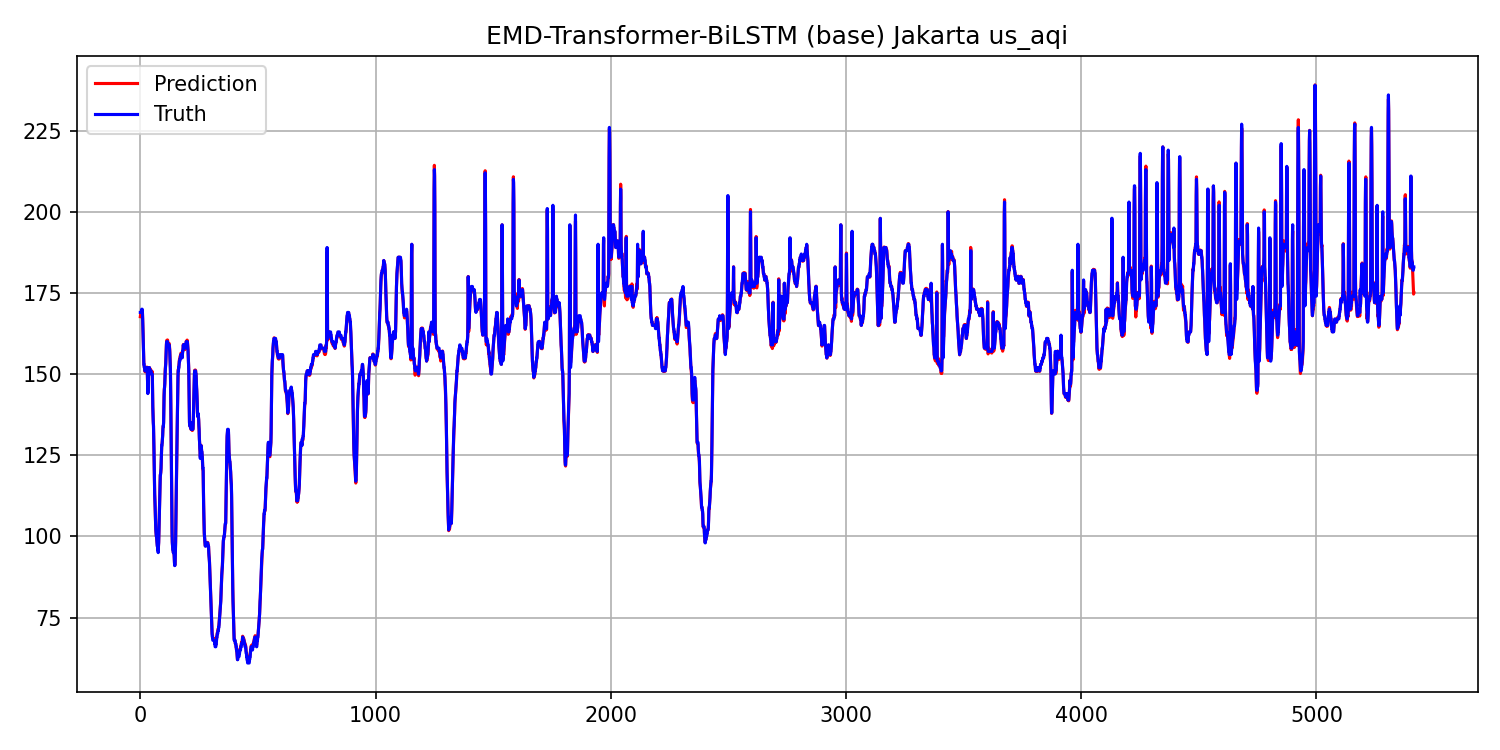

--- our_model/results/jakarta-us_aqi-base-2022-08-15_2026-10-01-exoimf-win5-h1.png ---


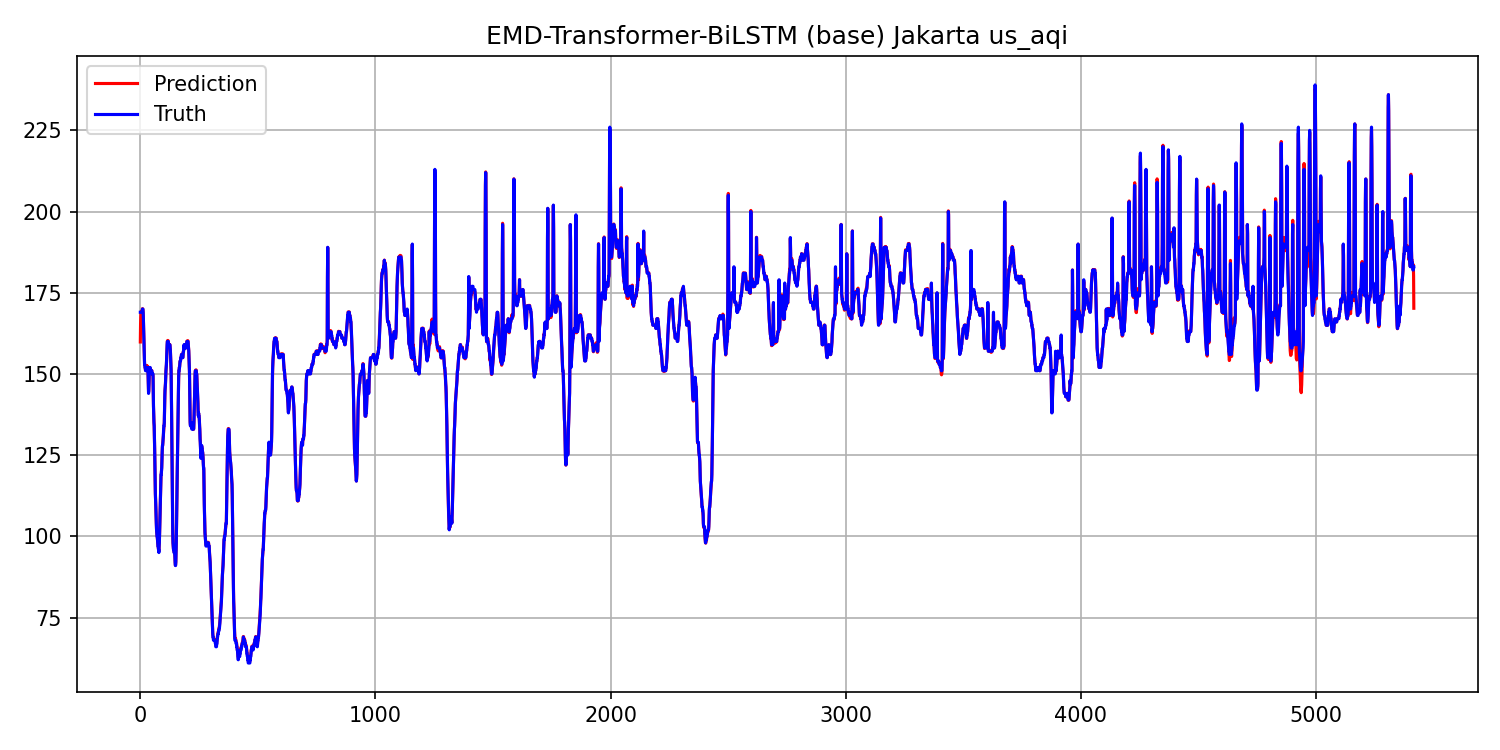

--- our_model/results/jakarta-us_aqi-weather-2022-08-15_2026-10-01-exoimf-leaksafe-win5-h1.png ---


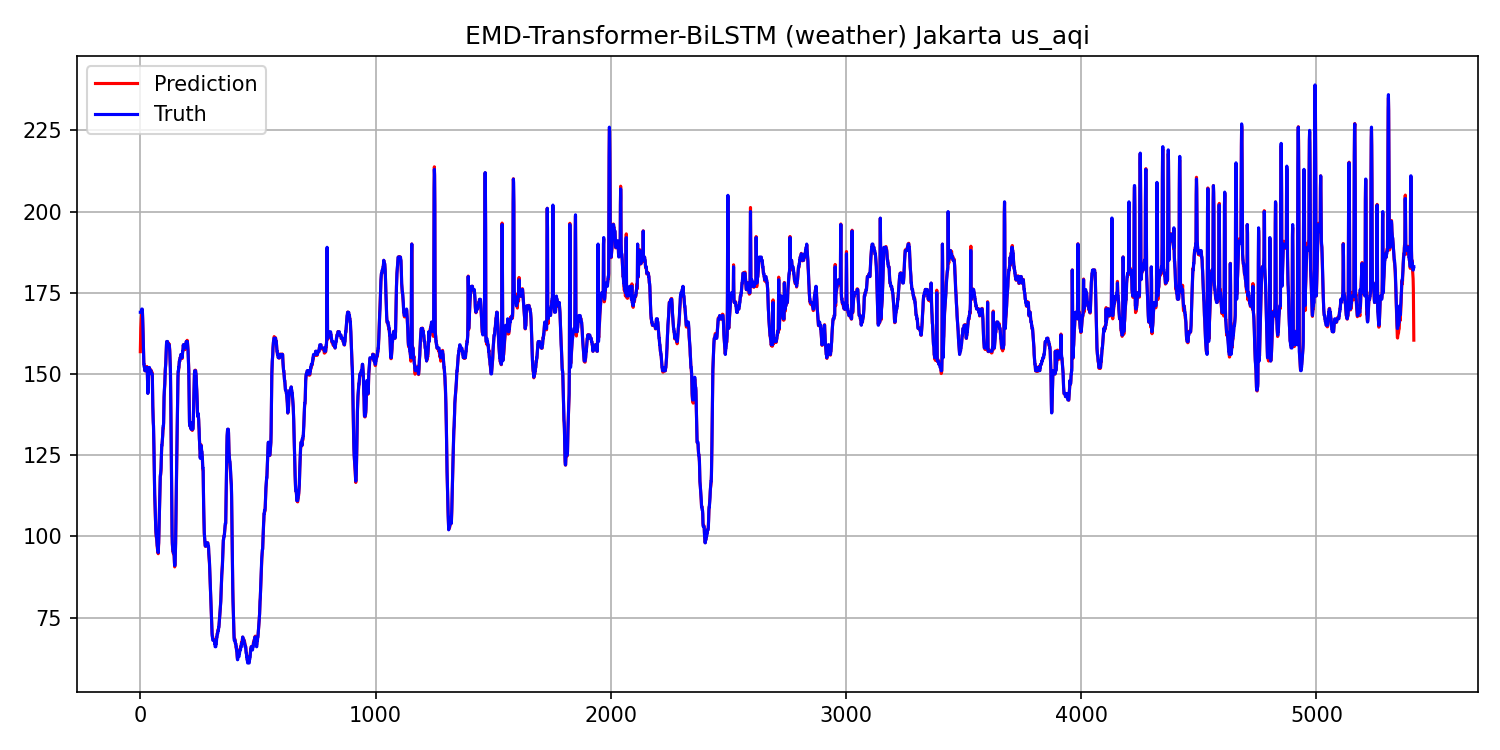

--- our_model/results/jakarta-us_aqi-weather-2022-08-15_2026-10-01-exoimf-win5-h1.png ---


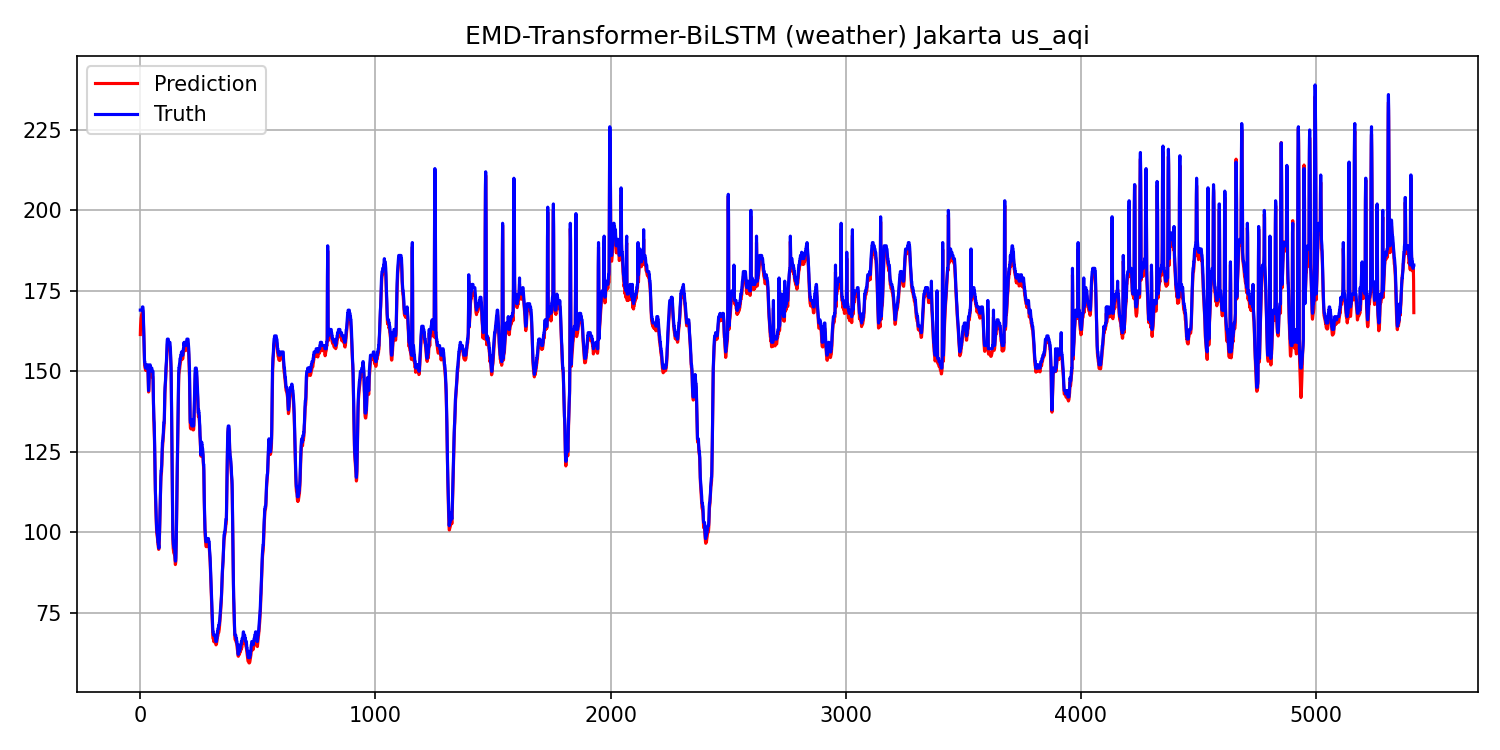


our_model/results/jakarta-us_aqi-base-2022-08-15_2026-10-01-exoimf-leaksafe-win5-h1.csv:
                        0          1      2
0                     NaN       pred  truth
1     2026-02-14 16:00:00  167.68272  169.0
2     2026-02-14 17:00:00  168.25201  169.0
3     2026-02-14 18:00:00   168.3755  169.0
4     2026-02-14 19:00:00  168.39252  169.0
...                   ...        ...    ...
5411  2026-09-28 02:00:00  180.19511  182.0
5412  2026-09-28 03:00:00  179.33957  182.0
5413  2026-09-28 04:00:00  177.10251  182.0
5414  2026-09-28 05:00:00   174.6454  183.0
5415  2026-09-28 06:00:00  175.05836  183.0

[5416 rows x 3 columns]

our_model/results/jakarta-us_aqi-base-2022-08-15_2026-10-01-exoimf-win5-h1.csv:
                        0          1      2
0                     NaN       pred  truth
1     2026-02-14 13:00:00  159.84999  169.0
2     2026-02-14 14:00:00   165.2946  169.0
3     2026-02-14 15:00:00  167.85799  169.0
4     2026-02-14 16:00:00  168.92691  169.0
...         

In [8]:
from IPython.display import Image, display
import glob, pandas as pd

for f in sorted(glob.glob("our_model/results/*.png")):
    print(f"--- {f} ---"); display(Image(filename=f))
for f in sorted(glob.glob("our_model/results/*.csv")):
    print(f"\n{f}:"); print(pd.read_csv(f, header=None))

In [9]:
# Ringkas hasil jadi satu arsip kecil di /kaggle/working (ikut Save Version)
import shutil, os

os.makedirs("/kaggle/working/outputs", exist_ok=True)
for f in glob.glob("our_model/results/*.log") + glob.glob("our_model/results/*.csv") + glob.glob("our_model/results/*.png"):
    shutil.copy(f, "/kaggle/working/outputs/")
shutil.make_archive("/kaggle/working/results-kaggle", "zip", "our_model/results")
print(sorted(os.listdir("/kaggle/working/outputs")))

['full_base.log', 'full_base_leaksafe.log', 'full_weather.log', 'full_weather_leaksafe.log', 'jakarta-us_aqi-base-2022-08-15_2026-10-01-exoimf-leaksafe-win5-h1.csv', 'jakarta-us_aqi-base-2022-08-15_2026-10-01-exoimf-leaksafe-win5-h1.png', 'jakarta-us_aqi-base-2022-08-15_2026-10-01-exoimf-win5-h1.csv', 'jakarta-us_aqi-base-2022-08-15_2026-10-01-exoimf-win5-h1.png', 'jakarta-us_aqi-base_smoke-win5-h1.csv', 'jakarta-us_aqi-weather-2022-08-15_2026-10-01-exoimf-leaksafe-win5-h1.csv', 'jakarta-us_aqi-weather-2022-08-15_2026-10-01-exoimf-leaksafe-win5-h1.png', 'jakarta-us_aqi-weather-2022-08-15_2026-10-01-exoimf-win5-h1.csv', 'jakarta-us_aqi-weather-2022-08-15_2026-10-01-exoimf-win5-h1.png', 'jakarta-us_aqi-weather_smoke-win5-h1.csv']
